# 01 – Cleaning the training set

Goal: produce **one clean training set**, `splits/clean_train.csv`, to be compared and merged with the other team members' versions. **Only after** this agreement are the folds generated (notebook `02_validation_setup`).

| # | step | decision |
|---|---|---|
| 1 | **copies**: training images that are modified copies of other training images (star pattern) | removed |
| 2 | **ambiguous groups**: the same image with two labels, without knowing which one is the original | decided case by case, by eye |
| 3 | **instrument artefacts** (bands, streaks, saturated channels) | kept, flagged `artifact` |
| 4 | **empty images** | removed |
| 5 | **suspicious labels** (a model confidently contradicts them) | kept, flagged `review` |

The final file has one row for **each** of the 4,328 training images, with its status and a `keep` column (True = part of the clean training set).

Requires `outputs/meta.csv` and the embeddings written by `00_eda`.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common as C

plt.rcParams["figure.dpi"] = 80
meta = pd.read_csv(C.OUT / "meta.csv")
print("DATA =", C.DATA)

DATA = /home/elia/ANN-DL-Challenge/data


## 1. Copies: finding them with the star pattern

Comparing images by their **content** (e.g. DINOv2 embeddings) misses many copies, because brightening changes the appearance too much.

A better idea (suggested by a teammate) is to look at the **stars in the background**. Two pictures of the same patch of sky have their stars in **exactly the same positions**, even if one was brightened, made grainy or partly covered by an alien. Two different galaxies have stars in completely unrelated positions.

The "star descriptor" of each image is built as follows:
1. grayscale and `log`, to reduce the effect of brightening;
2. **band-pass filter** (difference of two Gaussian blurs, sigma 1.5 and 5): small bright points (the stars) remain, while the uniform background, broad gradients and the galaxy core disappear;
3. keep only the positive values (the peaks) and **mask the central disc**, where the galaxy and often the alien are;
4. normalise the vector, so that the dot product between two descriptors is a correlation (1 = same stars, 0 = unrelated).

Then every training image is compared with all the others.

In [2]:
import torch
from scipy.ndimage import gaussian_filter

tr = meta[meta.split == "train"].reset_index(drop=True)
yy, xx = np.indices((256, 256))
outside = np.hypot(yy - 128, xx - 128) > 70                  # outside the central disc
outside[1::2, :] = False; outside[:, 1::2] = False           # one pixel out of 4: enough, and saves memory

def star_descriptor(img_id):
    g = np.log1p(np.asarray(C.load_image(img_id).convert("L"), np.float32))
    band = np.clip(gaussian_filter(g, 1.5) - gaussian_filter(g, 5), 0, None)   # peaks only
    v = band[outside]
    v = v - v.mean()
    return (v / (np.linalg.norm(v) + 1e-6)).astype(np.float32)

X = torch.tensor(np.stack([star_descriptor(i) for i in tr.id]))
SIM = (X @ X.T).numpy()                     # correlation between every pair of images
np.fill_diagonal(SIM, -1)                   # ignore the comparison of an image with itself
print(SIM.shape)

(4328, 4328)


We look at the pairs with correlation > 0.2, split by whether they contain an alien. The reason: every alien is **the same drawing**, which often extends outside the central disc and creates a false similarity between two alien images.

In [3]:
al = tr.alien.to_numpy()
i, j = np.where(np.triu(SIM > 0.2))
s = SIM[i, j]
bins = [0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
pd.DataFrame({
    "no alien":         np.histogram(s[~al[i] & ~al[j]], bins)[0],
    "alien + alien":    np.histogram(s[al[i] & al[j]], bins)[0],
    "alien + no alien": np.histogram(s[al[i] ^ al[j]], bins)[0],
}, index=[f"{a}-{b}" for a, b in zip(bins[:-1], bins[1:])])

,no alien,alien + alien,alien + no alien
0.2-0.3,12,134,0
0.3-0.5,0,88,55
0.5-0.7,0,16,262
0.7-0.9,2,0,119
0.9-1.0,1341,0,0


**How to read it.**
- **No alien:** almost all pairs are **above 0.7**, then there is an **empty gap between 0.3 and 0.7**, then a few pairs between 0.2 and 0.3. Pairs above the gap are copies of the same picture, pairs below it are coincidences. The threshold goes **in the middle of the gap: 0.5**.
- **Alien + alien:** only low values, caused by the common drawing. Ignored.
- **Alien + no alien:** intermediate values (0.3–0.9). The alien covers part of the stars and lowers the correlation. Each alien image is linked to its **most similar** non-alien image. When the alien covers almost the whole sky the link is less certain, but this **does not change the clean set**: aliens are removed anyway; at worst we pick the wrong original for them.

### Visual check of the threshold
For each pair, compare the **stars in the background** (not the galaxy) of the top and bottom image:
- **A:** pairs without aliens with correlation 0.2–0.3 → expected: **different scenes**;
- **B:** pairs without aliens with correlation 0.7–0.9 → expected: **the same scene**, one of the two brightened;
- **C:** 6 random pairs above 0.9 → expected: **the same scene**;
- **D:** the 6 weakest alien → original links → the few stars visible around the alien should match.

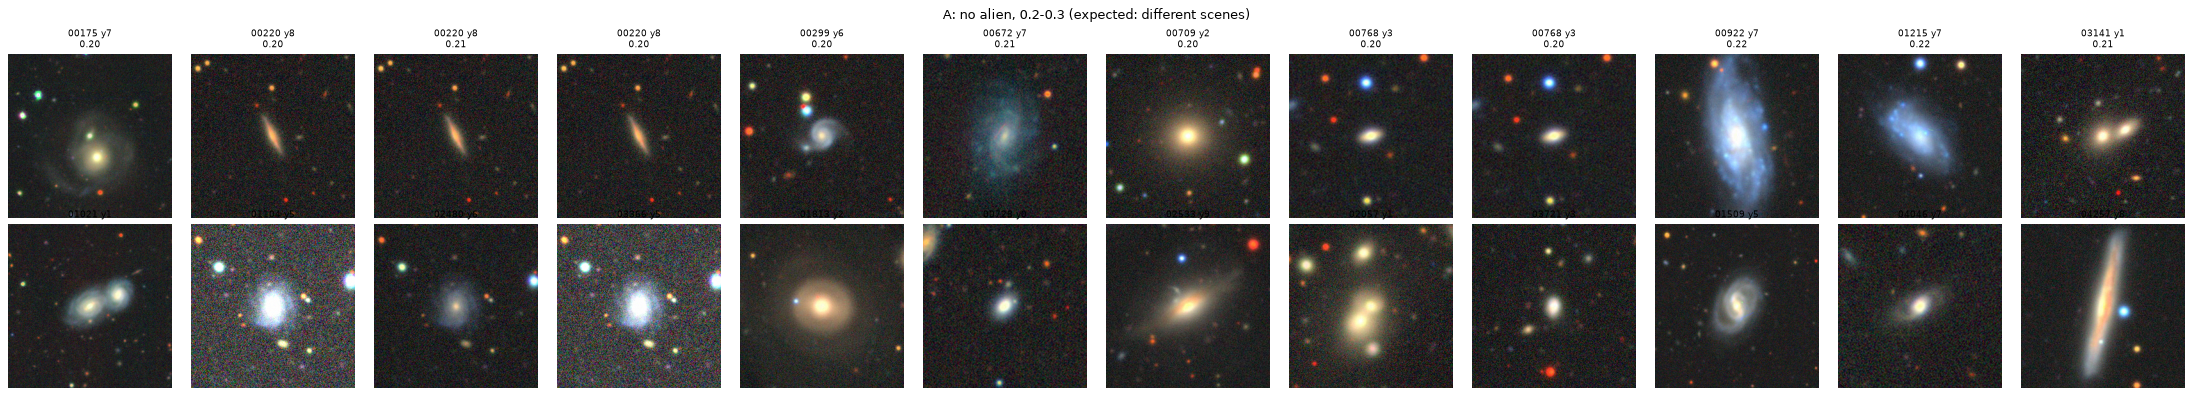

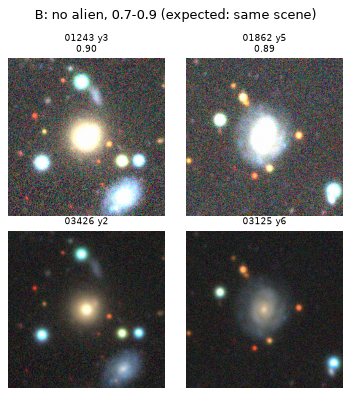

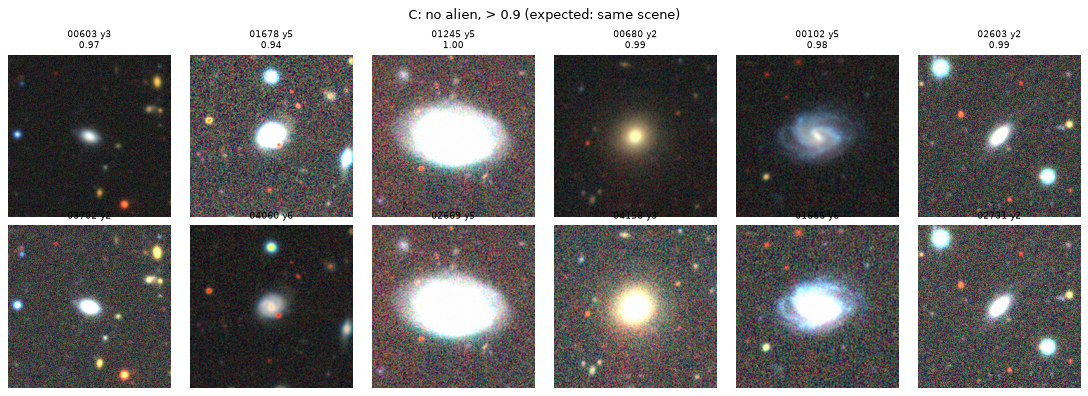

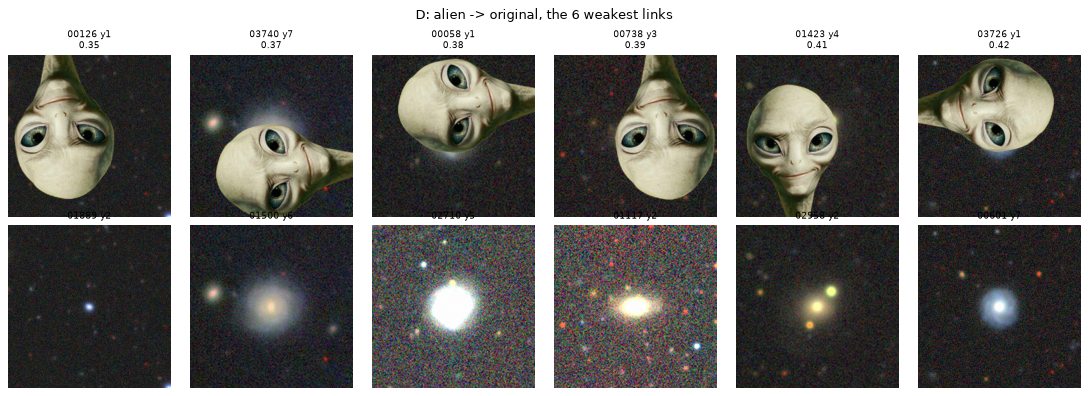

In [4]:
def show_pairs(pairs, title):
    fig, axes = plt.subplots(2, len(pairs), figsize=(2.3 * len(pairs), 5))
    for c, (a, b, v) in enumerate(pairs):
        for r, x in enumerate([a, b]):
            ax = axes[r, c]; ax.imshow(C.load_image(tr.id[x])); ax.axis("off")
            ax.set_title(f"{tr.id[x][6:]} y{int(tr.label[x])}" + (f"\n{v:.2f}" if r == 0 else ""), fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

nn = ~al[i] & ~al[j]
rng = np.random.default_rng(0)
show_pairs([(i[k], j[k], s[k]) for k in np.where(nn & (s < 0.3))[0]], "A: no alien, 0.2-0.3 (expected: different scenes)")
show_pairs([(i[k], j[k], s[k]) for k in np.where(nn & (s > 0.7) & (s < 0.9))[0]], "B: no alien, 0.7-0.9 (expected: same scene)")
show_pairs([(i[k], j[k], s[k]) for k in rng.choice(np.where(nn & (s > 0.9))[0], 6, replace=False)], "C: no alien, > 0.9 (expected: same scene)")
S_tmp = SIM.copy(); S_tmp[:, al] = -1
a_idx, a_best, a_val = np.where(al)[0], S_tmp[al].argmax(1), S_tmp[al].max(1)
show_pairs([(a_idx[k], a_best[k], a_val[k]) for k in np.argsort(a_val)[:6]], "D: alien -> original, the 6 weakest links")

**Outcome of the visual check (Elia, 26/11):** A: all different scenes; B and C: all the same scene; D: the stars around the alien match those of the original. The 0.5 threshold separates copies from coincidences correctly.

### From pairs to groups
With these links we build **groups** (connected components of a graph: if A≈B and B≈C, then A, B, C form one group). In each group:
- the **original** is the non-alien image with the **lowest brightness**, because the copies were brightened;
- all other images are **copies**;
- if the two darkest images have almost the same brightness (difference < 5), we cannot tell which one is the original: the group is flagged **ambiguous** (section 2).

In [5]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# links 1: pairs without aliens with correlation > 0.5 (in the empty gap 0.3-0.7)
I, J = [list(x[~al[i] & ~al[j] & (s > 0.5)]) for x in (i, j)]
# links 2: each alien -> the most similar image without alien
S_no_alien = SIM.copy(); S_no_alien[:, al] = -1
alien_idx = np.where(al)[0]
best = S_no_alien[al].argmax(1)
print(f"aliens: minimum correlation with their best non-alien match = {S_no_alien[al].max(1).min():.2f}")
I += list(alien_idx); J += list(best)

_, comp = connected_components(coo_matrix((np.ones(len(I)), (I, J)), shape=(len(tr),) * 2), directed=False)
size = np.bincount(comp)[comp]
tr["copy_group"] = np.where(size > 1, comp, -1)

# original = darkest non-alien image; the others = copies; ambiguous if the two darkest are almost equal
tr["is_copy"] = tr.alien.copy()
tr["original_id"] = None
tr["ambiguous"] = False
for gid, d in tr[tr.copy_group >= 0].groupby("copy_group"):
    cand = d[~d.alien].sort_values("mean")
    tr.loc[d.index, "original_id"] = cand.id.iloc[0]
    if len(cand) >= 2 and cand["mean"].iloc[1] - cand["mean"].iloc[0] < 5:
        tr.loc[cand.index[cand["mean"] - cand["mean"].iloc[0] < 5], "ambiguous"] = True
    rest = cand.index[1:]                                   # all except the darkest
    tr.loc[rest[~tr.loc[rest, "ambiguous"].to_numpy()], "is_copy"] = True

print(f"groups: {tr[tr.copy_group >= 0].copy_group.nunique()}  |  copies: {tr.is_copy.sum()} "
      f"(with alien {(tr.is_copy & tr.alien).sum()}, brightened {(tr.is_copy & ~tr.alien).sum()})  |  "
      f"ambiguous: {tr.ambiguous.sum()}")
tr[["id", "copy_group", "is_copy", "original_id", "ambiguous"]].to_csv(C.OUT / "copies.csv", index=False)

aliens: minimum correlation with their best non-alien match = 0.35
groups: 967  |  copies: 1328 (with alien 332, brightened 996)  |  ambiguous: 6


### The labels of the copies
The decisive question: does a copy have the **same label** as its original?

In [6]:
lab = tr.set_index("id").label
cp = tr[tr.is_copy].copy()
cp["original_label"] = lab[cp.original_id].values
cp["kind"] = np.where(cp.alien, "with alien", "brightened")
for kind, d in cp.groupby("kind"):
    print(f"{kind:11s}: {(d.label == d.original_label).mean():.1%} have the same label as their original ({len(d)} copies)")
pd.crosstab(cp[cp.kind == "brightened"].original_label.astype(int).rename("original label"),
            cp[cp.kind == "brightened"].label.astype(int).rename("label of the brightened copy"))

brightened : 0.0% have the same label as their original (996 copies)
with alien : 9.9% have the same label as their original (332 copies)


label of the brightened copy,2,3,5,6
original label,,,,
0,0,1,0,0
2,0,301,0,0
3,259,0,0,0
5,0,0,0,232
6,0,0,203,0


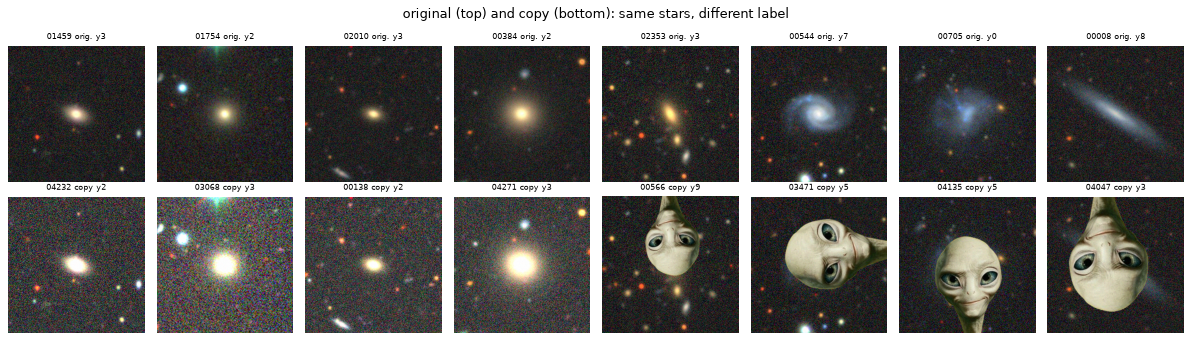

In [7]:
# examples: original on top, one of its copies below
ex = cp.groupby("kind").sample(4, random_state=0)
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for c, r in enumerate(ex.itertuples()):
    axes[0, c].imshow(C.load_image(r.original_id)); axes[0, c].set_title(f"{r.original_id[6:]} orig. y{int(r.original_label)}", fontsize=7)
    axes[1, c].imshow(C.load_image(r.id)); axes[1, c].set_title(f"{r.id[6:]} copy y{int(r.label)}", fontsize=7)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("original (top) and copy (bottom): same stars, different label"); plt.tight_layout(); plt.show()

**What we found.** This is the most important finding about the data.
- **Brightened copies always carry a wrong label**, swapped systematically: 2↔3 (round ↔ in-between smooth) and 5↔6 (barred ↔ tight spiral). These are exactly the hardest pairs of classes, so it is a targeted corruption.
- **Alien images are copies too**, with a **random** label. The ~10% that match the original are pure chance (1 in 10).
- The originals **are already in the training set**: removing the copies loses no galaxy.

Consequences:
1. copies are **removed from training**: they would teach exactly the 2↔3 and 5↔6 confusions;
2. the "brightness → class shortcut" seen in the EDA was in fact this trap of wrong labels: there is nothing to "normalise and recover".

## 2. Ambiguous groups

In 3 groups, two images are **the same, non-brightened picture with two different labels**. The "darkest image is the original" rule does not work because they have the same brightness. We look at them one by one.

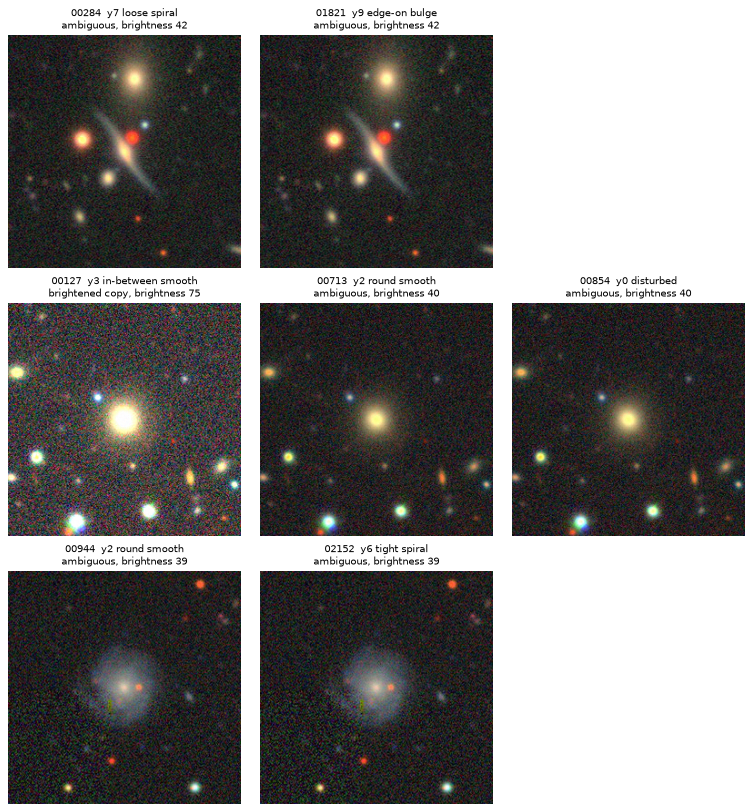

In [8]:
amb_groups = tr[tr.ambiguous].copy_group.unique()
rows = [tr[tr.copy_group == g] for g in amb_groups]
n = max(len(r) for r in rows)
fig, axes = plt.subplots(len(rows), n, figsize=(3.2 * n, 3.4 * len(rows)))
for k, d in enumerate(rows):
    for j in range(n):
        ax = axes[k, j]; ax.axis("off")
        if j < len(d):
            r = d.iloc[j]
            kind = "brightened copy" if r.is_copy else "ambiguous"
            ax.imshow(C.load_image(r.id))
            ax.set_title(f"{r.id[6:]}  y{int(r.label)} {C.CLASSES[int(r.label)]}\n{kind}, brightness {r['mean']:.0f}", fontsize=9)
plt.tight_layout(); plt.show()

**Decisions** (taken by looking at the images).
1. **`00713` (round smooth) / `00854` (disturbed):** a smooth, round elliptical galaxy → class **2**. Confirmed by the brightened copy in the same group, `00127`, labelled **3**: copies always swap 2↔3, so the original label was 2. Keep `00713`, drop `00854`.
2. **`00284` (loose spiral) / `01821` (edge-on bulge):** an edge-on disc with a central bulge → class **9**. Keep `01821`, drop `00284`.
3. **`00944` (round smooth) / `02152` (tight spiral):** tightly wound spiral arms are visible → class **6**. Keep `02152`, drop `00944`.

The decisions live in the set below, so they can be changed in one place if the team decides otherwise.

In [9]:
AMBIGUOUS_KEEP = {"train_00713", "train_01821", "train_02152"}   # among the ambiguous images, the ones we keep
tr["keep_ambiguous"] = tr.id.isin(AMBIGUOUS_KEEP)
print(tr[tr.ambiguous][["id", "label", "keep_ambiguous"]].to_string(index=False))

         id  label  keep_ambiguous
train_00284    7.0           False
train_00713    2.0            True
train_00854    0.0           False
train_00944    2.0           False
train_01821    9.0            True
train_02152    6.0            True


## 3. Instrument artefacts

Some originals have **coloured bands or streaks** (satellite trails, saturated sensor channels). We find them by counting pixels where one channel is very high and another very low, i.e. pure colours that are unnatural for the sky.

These images are **not sabotage**: they are real defects of the data, also present **in the test** (e.g. `test_12044`). We keep them, because learning to ignore them is useful, and flag them with `artifact = True` for information only.

images with artefacts: 13


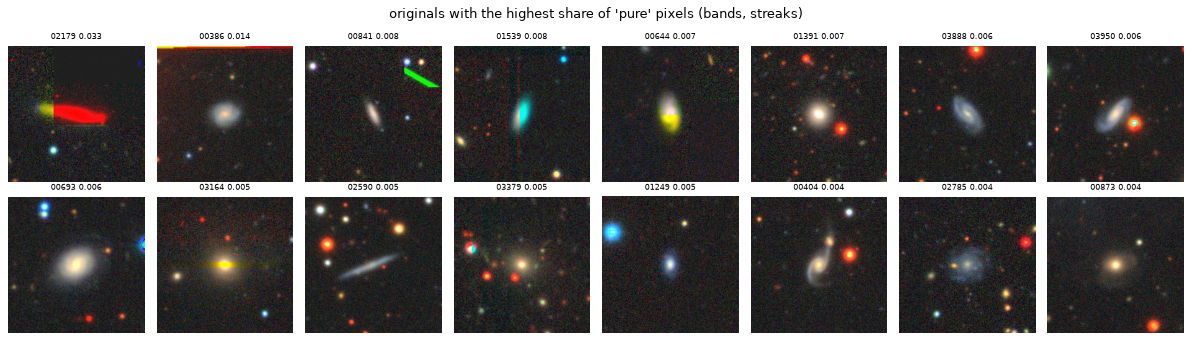

In [10]:
def band_fraction(img_id):
    a = np.asarray(C.load_image(img_id), np.int16)
    return ((a.max(2) > 200) & (a.min(2) < 60)).mean()     # share of "pure", bright-coloured pixels

orig = tr[~tr.is_copy].copy()
orig["band"] = [band_fraction(i) for i in orig.id]
tr["artifact"] = tr.id.isin(orig[orig.band > 0.005].id)
print("images with artefacts:", tr.artifact.sum())
ex = orig.nlargest(16, "band")
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for ax, r in zip(axes.ravel(), ex.itertuples()):
    ax.imshow(C.load_image(r.id)); ax.set_title(f"{r.id[6:]} {r.band:.3f}", fontsize=7); ax.axis("off")
fig.suptitle("originals with the highest share of 'pure' pixels (bands, streaks)"); plt.tight_layout(); plt.show()

## 4. Empty images
Only one: `train_03848`, a uniform grey square with no galaxy, found in the EDA. Removed.

## 5. Suspicious labels

On all the clean originals we train the **linear probe** of the EDA (logistic regression on the DINOv2 embeddings) with a 5-fold cross-validation, so that every image gets an **out-of-fold** prediction from a model that did not see it.

An image is flagged `review = True` if:
- the model gives its label a probability **< 0.05**,
- **and** it is confident about another class, with probability **> 0.7**.

This is the *confident learning* criterion (as in cleanlab): it flags only **clear** disagreements.

**Careful:** the linear probe is not a strong model (F1 ≈ 0.63), so the list contains both likely label errors and galaxies that are simply hard. That is why these images **are kept**: the column is there for future experiments, and the list can be recomputed later with the fine-tuned CNN, which will be more reliable.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

E = np.load(C.OUT / "emb_dinov2_s.npy")
row_of = {i: k for k, i in enumerate(pd.read_csv(C.OUT / "emb_dinov2_s_ids.csv").id)}
keep_now = tr[(~tr.is_copy) & (~tr.ambiguous | tr.keep_ambiguous) & ~tr.id.isin(C.EMPTY_IDS)]
Xk, yk = E[[row_of[i] for i in keep_now.id]], keep_now.label.astype(int).to_numpy()
P = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.05)), Xk, yk,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
p_label, pred, p_pred = P[np.arange(len(yk)), yk], P.argmax(1), P.max(1)
review = (p_label < 0.05) & (p_pred > 0.7)
tr["review"] = tr.id.isin(keep_now.id[review])
tr["review_pred"] = pd.Series(pred, index=keep_now.index).where(pd.Series(review, index=keep_now.index))
print(f"labels to review: {review.sum()} ({100*review.mean():.1f}% of the clean training set)")
pd.crosstab(pd.Series(yk[review], name="label"), pd.Series(pred[review], name="predicted by the model"))

labels to review: 126 (4.2% of the clean training set)


predicted by the model,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,0,7,7,7,1,1,0,6,0,2
1,0,0,1,1,0,2,0,4,1,1
2,0,3,0,0,0,0,2,0,0,0
3,0,1,5,0,0,0,0,0,0,2
4,0,0,0,4,0,0,0,0,1,1
5,1,3,2,1,0,0,3,5,2,1
6,1,0,1,1,0,3,0,3,1,0
7,1,6,2,3,1,9,4,0,3,0
8,1,0,0,0,0,0,0,0,0,2


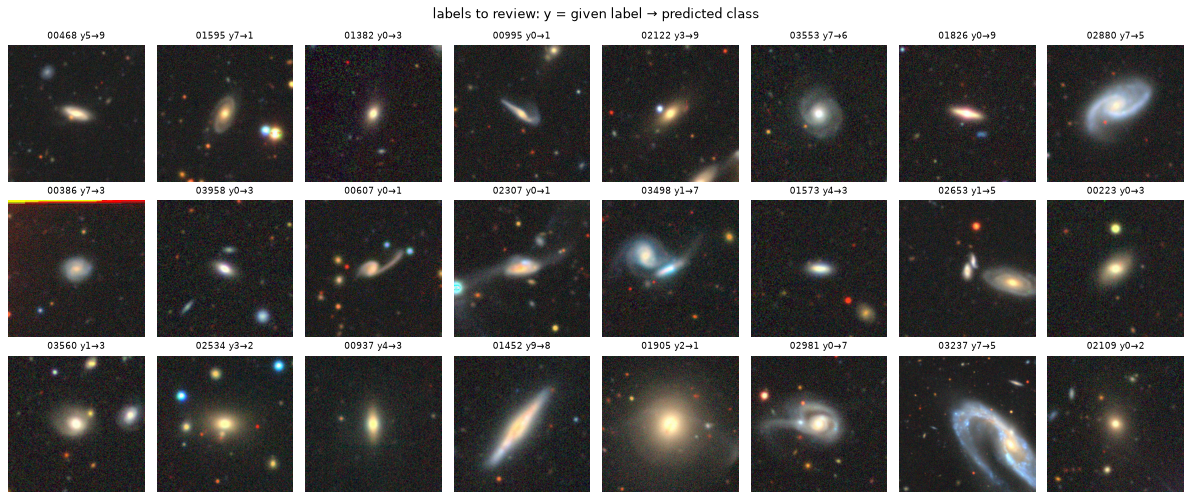

In [12]:
s = tr[tr.review].sample(24, random_state=0)
fig, axes = plt.subplots(3, 8, figsize=(15, 6.4))
for ax, r in zip(axes.ravel(), s.itertuples()):
    ax.imshow(C.load_image(r.id)); ax.set_title(f"{r.id[6:]} y{int(r.label)}→{int(r.review_pred)}", fontsize=8); ax.axis("off")
fig.suptitle("labels to review: y = given label → predicted class"); plt.tight_layout(); plt.show()

**Reading.** Some cases really look mislabelled (e.g. an edge-on galaxy labelled *disturbed*), others are ambiguous between neighbouring classes (spirals 5/6/7, *disturbed* vs *loose spiral*). The most frequent disagreements involve classes 0 and 7, the same ones the model confuses in general.

## 6. The clean training set

We summarise the status of every image and save `splits/clean_train.csv`.

| column | meaning |
|---|---|
| `status` | `clean`, `copy_brightened`, `copy_alien`, `ambiguous_kept`, `ambiguous_dropped`, `empty` |
| `keep` | **True = part of the clean training set** |
| `original_id` | for copies, the image they derive from |
| `artifact` | the image has bands or streaks (kept, informative only) |
| `review` | suspicious label (kept, to be used in experiments) |
| `review_pred` | the class the model would have predicted |

In [13]:
tr["status"] = np.select(
    [tr.id.isin(C.EMPTY_IDS), tr.is_copy & tr.alien, tr.is_copy, tr.ambiguous & tr.keep_ambiguous, tr.ambiguous],
    ["empty", "copy_alien", "copy_brightened", "ambiguous_kept", "ambiguous_dropped"], "clean")
tr["keep"] = tr.status.isin(["clean", "ambiguous_kept"])
out = tr[["id", "label", "status", "keep", "original_id", "artifact", "review", "review_pred"]].copy()
out["label"] = out.label.astype(int)
out.to_csv(C.SPLITS / "clean_train.csv", index=False)

print(out.status.value_counts().to_string(), "\n")
summary = out.groupby("label").agg(before=("id", "size"), after=("keep", "sum"),
                                   review=("review", "sum"), artifact=("artifact", "sum"))
summary.index = [f"{c} {C.CLASSES[c]}" for c in summary.index]
summary.loc["total"] = summary.sum()
summary

status
clean                2993
copy_brightened       996
copy_alien            332
ambiguous_dropped       3
ambiguous_kept          3
empty                   1 



,before,after,review,artifact
0 disturbed,213,182,31,0
1 merging,345,313,10,0
2 round smooth,744,446,5,3
3 in-between smooth,685,343,8,1
4 cigar,83,56,6,2
5 barred spiral,584,346,18,2
6 tight spiral,565,309,10,1
7 loose spiral,477,444,29,2
8 edge-on no bulge,276,240,3,2
9 edge-on bulge,356,317,6,0


## Summary

- The clean training set contains **2,996 images** (`keep = True`): all the originals, without copies or empty images.
- Classes 2, 3, 5 and 6 lose the most (the brightened copies were all there); class 4 (*cigar*) goes from 83 to **56** real images.
- Instrument **artefacts** are kept, because they also exist in the test.
- **Suspicious labels** (~4%) are kept and flagged: the team decides with an experiment whether to drop them or soften them with label smoothing.

**Next step:** compare `clean_train.csv` with the other team members' lists, resolve the differences and freeze the file. Only then are the folds generated (`02_validation_setup`).